# Indonesian E-Commerce Customer Loyalty & Repeat Purchase Analysis
**End-to-End Exploratory Data Analysis (EDA) di Google Colab**

### Ruang Lingkup Analisis

# Indonesian E-Commerce Customer Loyalty & Repeat Purchase Analysis
## End-to-End Exploratory Data Analysis (EDA) di Google Colab

### Ruang Lingkup Analisis
1. **Persiapan & Pembersihan Data** — Memuat dataset, membersihkan anomali kategori (`E -> Body Treatment`, `Convinience Goods -> Convenience Goods`), menambah fitur turunan (`month`, `weekday`, `age_group`), serta menyimpan `transactions_clean.csv`.
2. **Customer Behavior Analysis** — Mengukur total transaksi, pelanggan unik, distribusi usia & gender, wilayah pelanggan, produk & kategori terpopuler, serta aktivitas bulanan (Juni vs Juli 2022).
3. **Repeat Purchase Analysis** — Membandingkan One-Time vs Repeat Customers, menghitung Repeat Purchase Rate, distribusi frekuensi pembelian, pelanggan dengan transaksi terbanyak, serta kategori favorit repeat customers.
4. **RMF Customer Segmentation Analysis** — Menghitung *Recency* (jarak hari sejak transaksi terakhir), *Frequency* (`n_trx`), dan *Monetary/Volume* (`total_qty`), menyusun skor `R`, `F`, `M` (skala 1–3), mengelompokkan pelanggan ke segmen (`Champions`, `Loyal (mulai menjauh)`, `Aktif / Potensial`, `At Risk`, `Lost / Hibernating`, `Perlu Perhatian`), menyusun tabel ringkasan per segmen, serta menyimpan `customer_summary.csv`.
5. **Monthly Customer Retention Analysis** — Menghitung pelanggan aktif Juni & Juli, pelanggan yang bertransaksi di kedua bulan, persentase retensi Juni ke Juli, serta perbandingan pelanggan yang kembali dan tidak kembali.



## 1. Import Library
Menggunakan library standar Python yang sudah tersedia secara bawaan di Google Colab (`pandas`, `numpy`, `matplotlib`, `seaborn`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan tabel dan gaya grafik
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid')

print("Library berhasil dimuat!")

Library berhasil dimuat!


## 2. Memuat Dataset

In [3]:
import pandas as pd

# Baca file CSV mentah
df = pd.read_csv("repeatbuyer_ecommerce_indo.csv")

# Cek 5 baris pertama
df.head()

,No,Trx_Date,Cust_ID,Age,Gender,AREA,Product_ID,Product_Name,Category,Amount
0,1,6/1/2022,CTR0200437,49,Laki-laki,Aceh,HP-PV15,Laptop HP Pavilion 15,Computer,1
1,2,6/1/2022,CTR0200460,18,Perempuan,Bandung,192021232,Hair Mask CDE,Hair Treatment,1
2,3,6/1/2022,CTR0200553,42,Perempuan,Banjarmasin,192021232,Hair Mask CDE,Hair Treatment,7
3,4,6/1/2022,CTR0200581,42,Laki-laki,Batam,IKE-KALLAX,Rak Buku IKEA Kallax,Home Appliances,5
4,5,6/1/2022,CTR0200563,39,Perempuan,Cirebon,232425275,Perfume OPQ,Cosmetics,1


## 3. Data Inspection & Data Cleaning
Pada tahap ini kita melakukan validasi dan standarisasi kolom agar selaras dengan skema `transactions_clean.csv`:
- Menyeragamkan nama kolom (`trx_id`, `trx_date`, `cust_id`, `age`, `gender`, `area`, `product_id`, `product_name`, `category`, `quantity`).
- Membersihkan spasi berlebih serta memperbaiki anomali kategori:
  - `'E'` (1 baris pada *Hand Cream HIJ*) -> `'Body Treatment'`
  - `'Convinience Goods'` (salah eja) -> `'Convenience Goods'`
- Mengonversi `trx_date` menjadi format tanggal dan menambahkan kolom `month`, `weekday`, serta `age_group`.

In [26]:
# 1. Cek missing values dan duplikasi
print("Missing values per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

# 2. Standarisasi nama kolom
rename_map = {
    'No': 'trx_id',
    'Trx_Date': 'trx_date',
    'Cust_ID': 'cust_id',
    'Age': 'age',
    'Gender': 'gender',
    'AREA': 'area',
    'Product_ID': 'product_id',
    'Product_Name': 'product_name',
    'Category': 'category',
    'Amount': 'quantity'
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

# 3. Bersihkan teks & anomali kategori
df['area'] = df['area'].astype(str).str.strip()
df['product_name'] = df['product_name'].astype(str).str.strip()
df['category'] = df['category'].replace({
    'E': 'Body Treatment',
    'Convinience Goods': 'Convenience Goods'
})

# 4. Konversi tanggal & buat kolom bantu
df['trx_date'] = pd.to_datetime(df['trx_date'])
df['month'] = df['trx_date'].dt.to_period('M').astype(str)
df['weekday'] = df['trx_date'].dt.day_name()
df['age_group'] = pd.cut(
    df['age'],
    bins=[17, 24, 34, 44, 60],
    labels=['18-24', '25-34', '35-44', '45-60']
)

# 5. Simpan hasil pembersihan transaksi ke transactions_clean.csv
transactions_clean = df.copy()
transactions_clean.to_csv('transactions_clean.csv', index=False)

print("\nData siap dianalisis! Jumlah kategori unik:", df['category'].nunique())
print("File 'transactions_clean.csv' berhasil disimpan dengan ukuran:", transactions_clean.shape)

display(transactions_clean.head())

Missing values per kolom:
trx_id          0
trx_date        0
cust_id         0
age             0
gender          0
area            0
product_id      0
product_name    0
category        0
quantity        0
month           0
weekday         0
age_group       0
dtype: int64

Jumlah baris duplikat: 0

Data siap dianalisis! Jumlah kategori unik: 13
File 'transactions_clean.csv' berhasil disimpan dengan ukuran: (1000, 13)


,trx_id,trx_date,cust_id,age,gender,area,product_id,product_name,category,quantity,month,weekday,age_group
0,1,2022-06-01,CTR0200437,49,Laki-laki,Aceh,HP-PV15,Laptop HP Pavilion 15,Computer,1,2022-06,Wednesday,45-60
1,2,2022-06-01,CTR0200460,18,Perempuan,Bandung,192021232,Hair Mask CDE,Hair Treatment,1,2022-06,Wednesday,18-24
2,3,2022-06-01,CTR0200553,42,Perempuan,Banjarmasin,192021232,Hair Mask CDE,Hair Treatment,7,2022-06,Wednesday,35-44
3,4,2022-06-01,CTR0200581,42,Laki-laki,Batam,IKE-KALLAX,Rak Buku IKEA Kallax,Home Appliances,5,2022-06,Wednesday,35-44
4,5,2022-06-01,CTR0200563,39,Perempuan,Cirebon,232425275,Perfume OPQ,Cosmetics,1,2022-06,Wednesday,35-44


## 4. Analisis 1: Customer Behavior Analysis
Menjawab pertanyaan bisnis mengenai:
- Jumlah pelanggan unik, total transaksi, dan total unit (`quantity`)
- Distribusi pelanggan berdasarkan usia dan gender
- Wilayah pelanggan teratas
- Produk dan kategori paling populer
- Aktivitas transaksi bulanan (Juni vs Juli 2022)

In [27]:
# A. Ringkasan Metrik Utama & Aktivitas Bulanan
total_trx = len(df)
unique_cust = df['cust_id'].nunique()
total_unit = df['quantity'].sum()

print(f"Total Transaksi   : {total_trx:,}")
print(f"Pelanggan Unik    : {unique_cust:,}")
print(f"Total Unit Dibeli : {total_unit:,}")

monthly_summary = df.groupby('month').agg(
    jumlah_transaksi=('trx_id', 'count'),
    pelanggan_unik=('cust_id', 'nunique'),
    total_unit=('quantity', 'sum')
).reset_index()

print("\n--- Aktivitas Transaksi Bulanan ---")
display(monthly_summary)

# B. Demografi Pelanggan Unik (Gender, Kelompok Usia, dan Wilayah Utama)
cust_demo = df.groupby('cust_id').agg(
    age=('age', 'first'),
    age_group=('age_group', 'first'),
    gender=('gender', 'first'),
    area_utama=('area', lambda x: x.mode()[0])
).reset_index()

print("\n--- Distribusi Gender Pelanggan Unik ---")
display(cust_demo['gender'].value_counts().rename_axis('gender').reset_index(name='jumlah_pelanggan'))

print("\n--- Distribusi Kelompok Usia Pelanggan Unik ---")
display(cust_demo['age_group'].value_counts().sort_index().rename_axis('age_group').reset_index(name='jumlah_pelanggan'))

print("\n--- Top 10 Wilayah Pelanggan (berdasarkan Jumlah Transaksi) ---")
top_area = df.groupby('area').agg(
    jumlah_transaksi=('trx_id', 'count'),
    pelanggan_unik=('cust_id', 'nunique')
).sort_values('jumlah_transaksi', ascending=False).head(10).reset_index()
display(top_area)

Total Transaksi   : 1,000
Pelanggan Unik    : 178
Total Unit Dibeli : 1,820

--- Aktivitas Transaksi Bulanan ---


,month,jumlah_transaksi,pelanggan_unik,total_unit
0,2022-06,504,105,925
1,2022-07,496,103,895



--- Distribusi Gender Pelanggan Unik ---


,gender,jumlah_pelanggan
0,Perempuan,101
1,Laki-laki,77



--- Distribusi Kelompok Usia Pelanggan Unik ---


,age_group,jumlah_pelanggan
0,18-24,18
1,25-34,25
2,35-44,74
3,45-60,61



--- Top 10 Wilayah Pelanggan (berdasarkan Jumlah Transaksi) ---


,area,jumlah_transaksi,pelanggan_unik
0,Medan,70,12
1,Manado,70,9
2,Semarang,66,8
3,Surabaya,63,6
4,Mataram,51,7
5,Tangerang,45,6
6,Pekanbaru,40,5
7,Yogyakarta,37,6
8,Samarinda,36,5
9,Padang,34,6


In [28]:
# C. Peringkat Kategori & Top 10 Produk Terpopuler
top_category = df.groupby('category').agg(
    jumlah_transaksi=('trx_id', 'count'),
    pelanggan_unik=('cust_id', 'nunique'),
    total_unit=('quantity', 'sum')
).sort_values('jumlah_transaksi', ascending=False).reset_index()
top_category['persen_transaksi'] = (top_category['jumlah_transaksi'] / total_trx) * 100

print("--- Seluruh Kategori Produk (13 Kategori) ---")
display(top_category)

top_products = df.groupby(['product_id', 'product_name', 'category']).agg(
    jumlah_transaksi=('trx_id', 'count'),
    total_unit=('quantity', 'sum')
).sort_values('jumlah_transaksi', ascending=False).head(10).reset_index()

print("\n--- Top 10 Produk Paling Sering Dibeli ---")
display(top_products)

--- Seluruh Kategori Produk (13 Kategori) ---


,category,jumlah_transaksi,pelanggan_unik,total_unit,persen_transaksi
0,Cosmetics,390,98,660,39.00
1,Electronics and Gadget,177,64,306,17.70
2,Body Treatment,133,65,260,13.30
3,Hair Treatment,94,57,213,9.40
4,Home Appliances,42,32,59,4.20
5,Computer,34,26,57,3.40
6,Kitchen Appliances,33,25,71,3.30
7,Fashion,29,20,46,2.90
8,Convenience Goods,26,21,47,2.60
9,Equipments,16,16,47,1.60



--- Top 10 Produk Paling Sering Dibeli ---


,product_id,product_name,category,jumlah_transaksi,total_unit
0,242526286,Whitening Cream RST,Cosmetics,34,53
1,778899001,Shampoo VWX,Hair Treatment,34,49
2,223344556,Sunscreen GHI,Body Treatment,32,51
3,181920212,Blush ZAB,Cosmetics,32,49
4,334455667,Body Lotion JKL,Body Treatment,30,65
5,161718191,Makeup Remover TUV,Cosmetics,29,41
6,202122242,Deodorant FGH,Cosmetics,28,67
7,141516171,Foot Cream NOP,Body Treatment,27,52
8,556677889,Face Mask PQR,Cosmetics,27,56
9,131415161,Face Oil KLM,Cosmetics,25,68


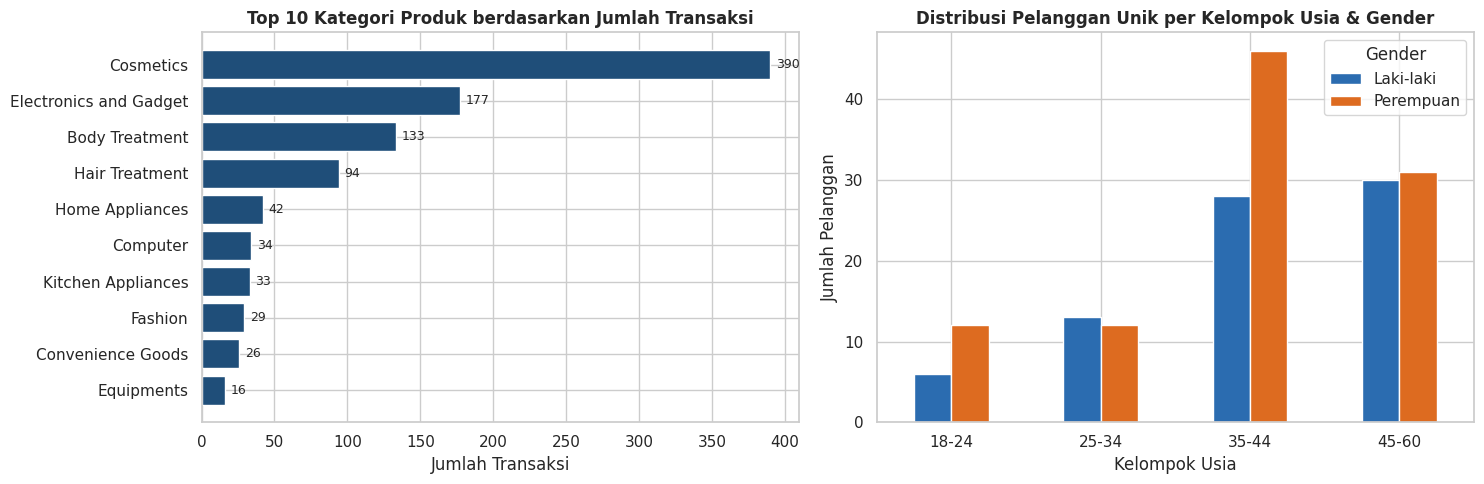

In [29]:
# Definisikan kembali top_category untuk memastikan visualisasi dapat berjalan mandiri
top_category = df.groupby('category').agg(
    jumlah_transaksi=('trx_id', 'count'),
    pelanggan_unik=('cust_id', 'nunique'),
    total_unit=('quantity', 'sum')
).sort_values('jumlah_transaksi', ascending=False).reset_index()

# Visualisasi Customer Behavior
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grafik 1: Top 10 Kategori
top10_cat = top_category.head(10).sort_values('jumlah_transaksi')
axes[0].barh(top10_cat['category'], top10_cat['jumlah_transaksi'], color='#1F4E79')
axes[0].set_title('Top 10 Kategori Produk berdasarkan Jumlah Transaksi', fontweight='bold')
axes[0].set_xlabel('Jumlah Transaksi')
for i, v in enumerate(top10_cat['jumlah_transaksi']):
    axes[0].text(v + 4, i, str(v), va='center', fontsize=9)

# Grafik 2: Kelompok Usia & Gender
age_gender = cust_demo.groupby(['age_group', 'gender'], observed=False).size().unstack(fill_value=0)
age_gender.plot(kind='bar', ax=axes[1], color=['#2B6CB0', '#DD6B20'], rot=0)
axes[1].set_title('Distribusi Pelanggan Unik per Kelompok Usia & Gender', fontweight='bold')
axes[1].set_xlabel('Kelompok Usia')
axes[1].set_ylabel('Jumlah Pelanggan')
axes[1].legend(title='Gender')

plt.tight_layout()
plt.show()

## 5. Analisis 2: Repeat Purchase Analysis
Menganalisis pola pembelian berulang:
- Perbandingan **One-Time Customers** (1 transaksi) vs **Repeat Customers** ($\ge 2$ transaksi)
- **Repeat Purchase Rate** selama periode Juni–Juli 2022
- Distribusi frekuensi transaksi per pelanggan
- Pelanggan dengan jumlah transaksi terbanyak
- Kategori produk paling populer di kalangan *repeat customers*

In [30]:
# Membuat tabel ringkasan per pelanggan (178 pelanggan unik)
customer_summary = df.groupby('cust_id').agg(
    first_date=('trx_date', 'min'),
    last_date=('trx_date', 'max'),
    n_trx=('trx_id', 'count'),
    total_qty=('quantity', 'sum'),
    age=('age', 'first'),
    gender=('gender', 'first'),
    age_group=('age_group', 'first'),
    area_utama=('area', lambda x: x.mode()[0])
).reset_index()

customer_summary['is_repeat'] = customer_summary['n_trx'] >= 2
customer_summary['first_month'] = customer_summary['first_date'].dt.to_period('M').astype(str)
customer_summary['span_hari'] = (customer_summary['last_date'] - customer_summary['first_date']).dt.days
customer_summary['tipe_pelanggan'] = np.where(
    customer_summary['is_repeat'], 'Repeat Customer (>=2x)', 'One-Time Customer (1x)'
)

repeat_summary = customer_summary['tipe_pelanggan'].value_counts().reset_index()
repeat_summary.columns = ['tipe_pelanggan', 'jumlah_pelanggan']
repeat_summary['persentase'] = (repeat_summary['jumlah_pelanggan'] / len(customer_summary)) * 100

print("--- Perbandingan One-Time vs Repeat Customers ---")
display(repeat_summary)

print("\n--- Statistik Deskriptif Frekuensi Transaksi & Total Unit per Pelanggan ---")
display(customer_summary[['n_trx', 'total_qty', 'span_hari']].describe().T)

print("\n--- Top 10 Pelanggan dengan Transaksi Terbanyak ---")
display(customer_summary.sort_values(['n_trx', 'total_qty'], ascending=False).head(10))

--- Perbandingan One-Time vs Repeat Customers ---


,tipe_pelanggan,jumlah_pelanggan,persentase
0,Repeat Customer (>=2x),167,93.82
1,One-Time Customer (1x),11,6.18



--- Statistik Deskriptif Frekuensi Transaksi & Total Unit per Pelanggan ---


,count,mean,std,min,25%,50%,75%,max
n_trx,178.00,5.62,4.27,1.00,3.00,4.00,7.00,26.00
total_qty,178.00,10.22,11.64,1.00,4.00,6.00,12.00,91.00
span_hari,178.00,9.56,15.98,0.00,2.00,3.00,8.00,60.00



--- Top 10 Pelanggan dengan Transaksi Terbanyak ---


,cust_id,first_date,last_date,n_trx,total_qty,age,gender,age_group,area_utama,is_repeat,first_month,span_hari,tipe_pelanggan
99,CTR0200510,2022-06-02,2022-07-06,26,61,44,Laki-laki,35-44,Surabaya,True,2022-06,34,Repeat Customer (>=2x)
31,CTR0200442,2022-06-07,2022-06-25,19,28,27,Laki-laki,25-34,Semarang,True,2022-06,18,Repeat Customer (>=2x)
154,CTR0200567,2022-06-10,2022-07-29,16,91,36,Perempuan,35-44,Aceh,True,2022-06,49,Repeat Customer (>=2x)
132,CTR0200545,2022-06-05,2022-06-20,16,48,52,Perempuan,45-60,Mataram,True,2022-06,15,Repeat Customer (>=2x)
21,CTR0200432,2022-06-12,2022-06-27,16,27,22,Perempuan,18-24,Pekanbaru,True,2022-06,15,Repeat Customer (>=2x)
88,CTR0200499,2022-07-14,2022-07-29,16,20,30,Perempuan,25-34,Manado,True,2022-07,15,Repeat Customer (>=2x)
89,CTR0200500,2022-06-01,2022-07-31,16,18,24,Laki-laki,18-24,Manado,True,2022-06,60,Repeat Customer (>=2x)
121,CTR0200532,2022-06-04,2022-07-15,15,50,49,Perempuan,45-60,Medan,True,2022-06,41,Repeat Customer (>=2x)
147,CTR0200560,2022-07-09,2022-07-23,15,48,44,Perempuan,35-44,Jember,True,2022-07,14,Repeat Customer (>=2x)
146,CTR0200559,2022-07-09,2022-07-23,15,22,39,Laki-laki,35-44,Banyuwangi,True,2022-07,14,Repeat Customer (>=2x)


--- Top 10 Kategori di Kalangan Repeat Customers ---


,category,transaksi_repeat,pelanggan_repeat,total_unit
0,Cosmetics,389,97,659
1,Electronics and Gadget,174,61,303
2,Body Treatment,133,65,260
3,Hair Treatment,92,55,211
4,Home Appliances,41,31,58
5,Kitchen Appliances,32,24,70
6,Computer,31,23,51
7,Fashion,29,20,46
8,Convenience Goods,26,21,47
9,Equipments,16,16,47


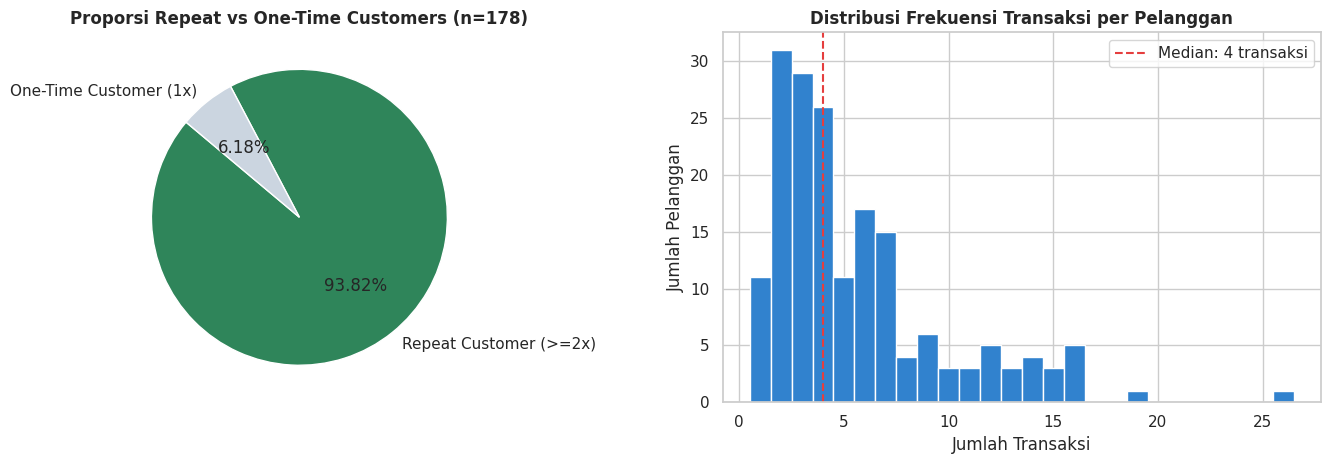

In [31]:
# Kategori populer di kalangan Repeat Customers
repeat_ids = set(customer_summary[customer_summary['is_repeat']]['cust_id'])
df_repeat = df[df['cust_id'].isin(repeat_ids)]

repeat_cat = df_repeat.groupby('category').agg(
    transaksi_repeat=('trx_id', 'count'),
    pelanggan_repeat=('cust_id', 'nunique'),
    total_unit=('quantity', 'sum')
).sort_values('transaksi_repeat', ascending=False).reset_index()

print("--- Top 10 Kategori di Kalangan Repeat Customers ---")
display(repeat_cat.head(10))

# Visualisasi Repeat Purchase
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].pie(
    repeat_summary['jumlah_pelanggan'],
    labels=repeat_summary['tipe_pelanggan'],
    autopct='%1.2f%%',
    startangle=140,
    colors=['#2F855A', '#CBD5E0']
)
axes[0].set_title('Proporsi Repeat vs One-Time Customers (n=178)', fontweight='bold')

axes[1].hist(
    customer_summary['n_trx'],
    bins=range(1, customer_summary['n_trx'].max() + 2),
    color='#3182CE',
    edgecolor='white',
    align='left'
)
axes[1].axvline(
    customer_summary['n_trx'].median(),
    color='#E53E3E',
    linestyle='--',
    label=f"Median: {customer_summary['n_trx'].median():.0f} transaksi"
)
axes[1].set_title('Distribusi Frekuensi Transaksi per Pelanggan', fontweight='bold')
axes[1].set_xlabel('Jumlah Transaksi')
axes[1].set_ylabel('Jumlah Pelanggan')
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Analisis 3: Monthly Customer Retention Analysis (Juni → Juli 2022)
Menghitung:
- Jumlah pelanggan aktif di bulan Juni dan Juli
- Jumlah pelanggan Juni yang kembali bertransaksi di bulan Juli (*Retained Customers*)
- Persentase retensi bulanan (*Monthly Retention Rate*)
- Perbandingan pelanggan yang kembali dan tidak kembali

,Kelompok Pelanggan,Jumlah Pelanggan
0,Aktif Juni 2022 (Total Kohort Juni),105
1,Aktif Juli 2022 (Total Aktif Juli),103
2,Kembali di Juli (Juni & Juli),30
3,Tidak Kembali di Juli (Hanya Juni),75
4,Baru Aktif di Juli (Hanya Juli),73


Monthly Retention Rate (Juni -> Juli): 30 / 105 = 28.57%


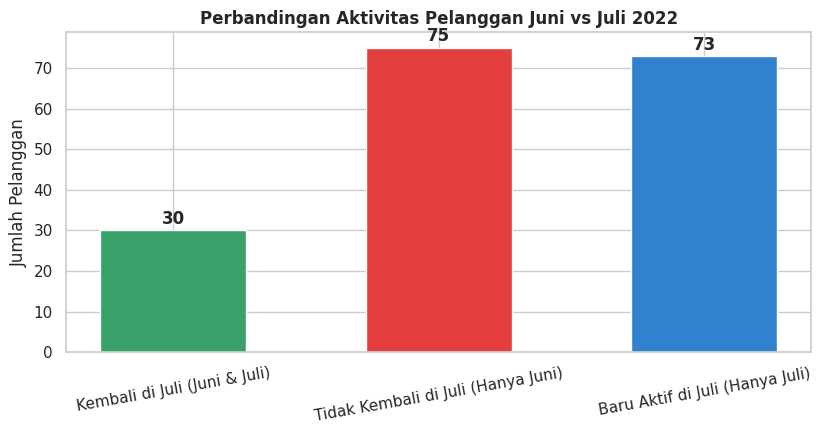

In [32]:
jun_customers = set(df[df['month'] == '2022-06']['cust_id'])
jul_customers = set(df[df['month'] == '2022-07']['cust_id'])

retained_customers = jun_customers & jul_customers   # Aktif Juni & kembali di Juli
churned_june = jun_customers - jul_customers         # Aktif Juni, tidak kembali di Juli
new_july = jul_customers - jun_customers             # Baru aktif di Juli

retention_rate = (len(retained_customers) / len(jun_customers)) * 100

retention_df = pd.DataFrame({
    'Kelompok Pelanggan': [
        'Aktif Juni 2022 (Total Kohort Juni)',
        'Aktif Juli 2022 (Total Aktif Juli)',
        'Kembali di Juli (Juni & Juli)',
        'Tidak Kembali di Juli (Hanya Juni)',
        'Baru Aktif di Juli (Hanya Juli)'
    ],
    'Jumlah Pelanggan': [
        len(jun_customers),
        len(jul_customers),
        len(retained_customers),
        len(churned_june),
        len(new_july)
    ]
})

display(retention_df)
print(f"Monthly Retention Rate (Juni -> Juli): {len(retained_customers)} / {len(jun_customers)} = {retention_rate:.2f}%")

# Visualisasi Perbandingan Pelanggan Juni vs Juli
plt.figure(figsize=(8.5, 4.5))
plot_ret = retention_df.iloc[2:].copy()
bars = plt.bar(
    plot_ret['Kelompok Pelanggan'],
    plot_ret['Jumlah Pelanggan'],
    color=['#38A169', '#E53E3E', '#3182CE'],
    width=0.55
)
plt.title('Perbandingan Aktivitas Pelanggan Juni vs Juli 2022', fontweight='bold')
plt.ylabel('Jumlah Pelanggan')
plt.xticks(rotation=10)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{int(h)}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## 7. RMF Analysis (Recency, Frequency, Monetary/Quantity)
Karena dataset belum memuat nilai rupiah (`price`/`revenue`), komponen **Monetary** diukur menggunakan **total unit pembelian (`total_qty`)** per pelanggan:
- **Recency (`recency_days`)**: selisih hari antara tanggal referensi (`max(trx_date) + 1 hari`) dan `last_date` pelanggan (semakin kecil nilainya, semakin baru bertransaksi).
- **Frequency (`frequency`)**: jumlah transaksi pelanggan (`n_trx`).
- **Monetary / Volume (`monetary_qty`)**: total unit barang yang dibeli pelanggan (`total_qty`).

In [34]:
import numpy as np
import pandas as pd

# Pastikan df_clean sudah tersedia dan tanggal sudah bertipe datetime
df_clean = df.copy()
df_clean['trx_date'] = pd.to_datetime(df_clean['trx_date'])

# Tanggal referensi = 1 hari setelah transaksi terakhir di dataset
reference_date = df_clean['trx_date'].max() + pd.Timedelta(days=1)

# Agregasi per pelanggan (termasuk age, gender, age_group & kolom repeat / pengulangan)
agg_dict = {
    'first_date': ('trx_date', 'min'),
    'last_date': ('trx_date', 'max'),
    'n_trx': ('trx_id', 'nunique') if 'trx_id' in df_clean.columns else ('trx_date', 'count'),
    'total_qty': ('quantity', 'sum'),
    'avg_qty_per_trx': ('quantity', 'mean'),
    'area_utama': ('area', lambda s: s.mode().iloc[0] if not s.mode().empty else None),
    'kategori_utama': ('category', lambda s: s.mode().iloc[0] if not s.mode().empty else None),
}

if 'age' in df_clean.columns:
    agg_dict['age'] = ('age', 'first')
if 'gender' in df_clean.columns:
    agg_dict['gender'] = ('gender', 'first')
if 'age_group' in df_clean.columns:
    agg_dict['age_group'] = ('age_group', 'first')

customer_clean = df_clean.groupby('cust_id', as_index=False).agg(**agg_dict)

# Kolom waktu & repeat / pengulangan
customer_clean['first_month'] = customer_clean['first_date'].dt.to_period('M').astype(str)
customer_clean['span_hari'] = (customer_clean['last_date'] - customer_clean['first_date']).dt.days
customer_clean['is_repeat'] = customer_clean['n_trx'] > 1
customer_clean['status_repeat'] = np.where(customer_clean['is_repeat'], 'Repeat (>1 Trx)', 'One-Time (1 Trx)')

# Metrik RMF (Monetary menggunakan total_qty karena belum ada kolom nilai rupiah)
customer_clean['recency_days'] = (reference_date - customer_clean['last_date']).dt.days
customer_clean['frequency'] = customer_clean['n_trx']
customer_clean['monetary_qty'] = customer_clean['total_qty']

# Skor R dan F skala 1-3 (R: 3 = paling baru, 1 = paling lama; F: 3 = paling sering, 1 = paling jarang)
customer_clean['R'] = pd.qcut(customer_clean['recency_days'], q=3, labels=[3, 2, 1], duplicates='drop').astype(int)
customer_clean['F'] = pd.qcut(customer_clean['frequency'].rank(method='first'), q=3, labels=[1, 2, 3]).astype(int)
customer_clean['M'] = pd.qcut(customer_clean['monetary_qty'].rank(method='first'), q=3, labels=[1, 2, 3]).astype(int)

def segmen(r):
    if r.R == 3 and r.F == 3:
        return "Champions"
    if r.F == 3 and r.R <= 2:
        return "Loyal (mulai menjauh)"
    if r.R == 3 and r.F <= 2:
        return "Aktif / Potensial"
    if r.R == 1 and r.F >= 2:
        return "At Risk"
    if r.R == 1 and r.F == 1:
        return "Lost / Hibernating"
    return "Perlu Perhatian"

customer_clean['segmen'] = customer_clean.apply(segmen, axis=1)

# Simpan & tampilkan hasil di Colab
customer_clean.to_csv('customer_summary.csv', index=False)
print("Ukuran customer_clean:", customer_clean.shape)
display(customer_clean.head(10))

Ukuran customer_clean: (178, 22)


,cust_id,first_date,last_date,n_trx,total_qty,avg_qty_per_trx,area_utama,kategori_utama,age,gender,age_group,first_month,span_hari,is_repeat,status_repeat,recency_days,frequency,monetary_qty,R,F,M,segmen
0,CTR0200411,2022-07-01,2022-07-04,4,5,1.25,Mataram,Cosmetics,18,Perempuan,18-24,2022-07,3,True,Repeat (>1 Trx),28,4,5,2,2,2,Perlu Perhatian
1,CTR0200412,2022-06-01,2022-07-31,6,6,1.00,Purwokerto,Cosmetics,38,Perempuan,35-44,2022-06,60,True,Repeat (>1 Trx),1,6,6,3,2,2,Aktif / Potensial
2,CTR0200413,2022-06-30,2022-07-12,13,19,1.46,Padang,Cosmetics,60,Perempuan,45-60,2022-06,12,True,Repeat (>1 Trx),20,13,19,2,3,3,Loyal (mulai menjauh)
3,CTR0200414,2022-07-04,2022-07-10,7,15,2.14,Yogyakarta,Cosmetics,27,Perempuan,25-34,2022-07,6,True,Repeat (>1 Trx),22,7,15,2,3,3,Loyal (mulai menjauh)
4,CTR0200415,2022-06-01,2022-07-31,11,15,1.36,Pekanbaru,Cosmetics,40,Perempuan,35-44,2022-06,60,True,Repeat (>1 Trx),1,11,15,3,3,3,Champions
5,CTR0200416,2022-06-22,2022-06-22,1,2,2.00,Manado,Computer,38,Laki-laki,35-44,2022-06,0,False,One-Time (1 Trx),40,1,2,1,1,1,Lost / Hibernating
6,CTR0200417,2022-06-13,2022-06-14,2,5,2.50,Bekasi,Electronics and Gadget,35,Laki-laki,35-44,2022-06,1,True,Repeat (>1 Trx),48,2,5,1,1,2,Lost / Hibernating
7,CTR0200418,2022-07-06,2022-07-12,7,10,1.43,Tangerang,Electronics and Gadget,45,Laki-laki,45-60,2022-07,6,True,Repeat (>1 Trx),20,7,10,2,3,2,Loyal (mulai menjauh)
8,CTR0200419,2022-07-18,2022-07-19,2,2,1.00,Jakarta,Body Treatment,49,Perempuan,45-60,2022-07,1,True,Repeat (>1 Trx),13,2,2,3,1,1,Aktif / Potensial
9,CTR0200420,2022-06-15,2022-06-18,4,6,1.50,Bekasi,Electronics and Gadget,36,Laki-laki,35-44,2022-06,3,True,Repeat (>1 Trx),44,4,6,1,2,2,At Risk


In [35]:
ringkasan_segmen = (
    customer_clean.groupby('segmen', as_index=False)
    .agg(
        pelanggan=('cust_id', 'count'),
        rata2_recency=('recency_days', 'mean'),
        rata2_frequency=('frequency', 'mean'),
        rata2_unit=('total_qty', 'mean')
    )
    .sort_values('pelanggan', ascending=False)
    .reset_index(drop=True)
)

ringkasan_segmen[['rata2_recency', 'rata2_frequency', 'rata2_unit']] = (
    ringkasan_segmen[['rata2_recency', 'rata2_frequency', 'rata2_unit']].round(1)
)

display(ringkasan_segmen)

,segmen,pelanggan,rata2_recency,rata2_frequency,rata2_unit
0,Perlu Perhatian,39,26.40,3.20,4.90
1,Aktif / Potensial,38,6.00,3.60,5.80
2,Loyal (mulai menjauh),38,33.80,10.40,19.20
3,Lost / Hibernating,26,47.70,2.00,4.20
4,Champions,22,5.20,10.20,19.80
5,At Risk,15,49.30,4.50,8.90


7. Custumer Summary

In [37]:
import numpy as np
import pandas as pd

# Pastikan df_clean / transactions_clean dan customer_summary sudah ada
df_src = transactions_clean.copy() if 'transactions_clean' in globals() else df.copy()
df_src['trx_date'] = pd.to_datetime(df_src['trx_date'])
customer_summary['last_date'] = pd.to_datetime(customer_summary['last_date'])

# 1. Tambahkan 3 kolom profil (age, gender, age_group) jika belum ada di customer_summary
for col in ['age', 'gender', 'age_group']:
    if col not in customer_summary.columns and col in df_src.columns:
        cust_profile = df_src.groupby('cust_id')[col].first()
        customer_summary[col] = customer_summary['cust_id'].map(cust_profile)

# 2. Hitung metrik & skor RMF (R, F, M) serta segmen
ref_date = df_src['trx_date'].max() + pd.Timedelta(days=1)
customer_summary['recency'] = (ref_date - customer_summary['last_date']).dt.days
customer_summary['frequency'] = customer_summary['n_trx']
customer_summary['monetary'] = customer_summary['total_qty']

customer_summary['R'] = pd.qcut(customer_summary['recency'], q=3, labels=[3, 2, 1], duplicates='drop').astype(int)
customer_summary['F'] = pd.qcut(customer_summary['frequency'].rank(method='first'), q=3, labels=[1, 2, 3]).astype(int)
customer_summary['M'] = pd.qcut(customer_summary['monetary'].rank(method='first'), q=3, labels=[1, 2, 3]).astype(int)

def segmen(r):
    if r.R == 3 and r.F == 3:
        return "Champions"
    if r.F == 3 and r.R <= 2:
        return "Loyal (mulai menjauh)"
    if r.R == 3 and r.F <= 2:
        return "Aktif / Potensial"
    if r.R == 1 and r.F >= 2:
        return "At Risk"
    if r.R == 1 and r.F == 1:
        return "Lost / Hibernating"
    return "Perlu Perhatian"

customer_summary['segmen'] = customer_summary.apply(segmen, axis=1)

# 3. Simpan & tampilkan hasilnya di Colab
customer_summary.to_csv('customer_summary.csv', index=False)
print("Kolom customer_summary sekarang:", list(customer_summary.columns))
display(customer_summary.head(10))


Kolom customer_summary sekarang: ['cust_id', 'first_date', 'last_date', 'n_trx', 'total_qty', 'age', 'gender', 'age_group', 'area_utama', 'is_repeat', 'first_month', 'span_hari', 'tipe_pelanggan', 'recency', 'frequency', 'monetary', 'R', 'F', 'M', 'segmen']


,cust_id,first_date,last_date,n_trx,total_qty,age,gender,age_group,area_utama,is_repeat,first_month,span_hari,tipe_pelanggan,recency,frequency,monetary,R,F,M,segmen
0,CTR0200411,2022-07-01,2022-07-04,4,5,18,Perempuan,18-24,Mataram,True,2022-07,3,Repeat Customer (>=2x),28,4,5,2,2,2,Perlu Perhatian
1,CTR0200412,2022-06-01,2022-07-31,6,6,38,Perempuan,35-44,Purwokerto,True,2022-06,60,Repeat Customer (>=2x),1,6,6,3,2,2,Aktif / Potensial
2,CTR0200413,2022-06-30,2022-07-12,13,19,60,Perempuan,45-60,Padang,True,2022-06,12,Repeat Customer (>=2x),20,13,19,2,3,3,Loyal (mulai menjauh)
3,CTR0200414,2022-07-04,2022-07-10,7,15,27,Perempuan,25-34,Yogyakarta,True,2022-07,6,Repeat Customer (>=2x),22,7,15,2,3,3,Loyal (mulai menjauh)
4,CTR0200415,2022-06-01,2022-07-31,11,15,40,Perempuan,35-44,Pekanbaru,True,2022-06,60,Repeat Customer (>=2x),1,11,15,3,3,3,Champions
5,CTR0200416,2022-06-22,2022-06-22,1,2,38,Laki-laki,35-44,Manado,False,2022-06,0,One-Time Customer (1x),40,1,2,1,1,1,Lost / Hibernating
6,CTR0200417,2022-06-13,2022-06-14,2,5,35,Laki-laki,35-44,Bekasi,True,2022-06,1,Repeat Customer (>=2x),48,2,5,1,1,2,Lost / Hibernating
7,CTR0200418,2022-07-06,2022-07-12,7,10,45,Laki-laki,45-60,Tangerang,True,2022-07,6,Repeat Customer (>=2x),20,7,10,2,3,2,Loyal (mulai menjauh)
8,CTR0200419,2022-07-18,2022-07-19,2,2,49,Perempuan,45-60,Jakarta,True,2022-07,1,Repeat Customer (>=2x),13,2,2,3,1,1,Aktif / Potensial
9,CTR0200420,2022-06-15,2022-06-18,4,6,36,Laki-laki,35-44,Bekasi,True,2022-06,3,Repeat Customer (>=2x),44,4,6,1,2,2,At Risk
